In [10]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [11]:
df = pd.read_csv('ScoreHalves_DREADDs.csv')
print(df.loc[df['Control']=='y',:])

    Group       Hab       Soc Control
0       1  0.138000  0.032667       y
1       2 -0.174000 -0.180000       y
3       4  0.182047  0.609333       y
4       5  0.083333  0.410000       y
5       6  0.024400  0.057667       y
7       8  0.071067 -0.104000       y
8       9 -0.134667 -0.081227       y
9      10 -0.071067  0.012000       y
10     11  0.061204  0.340000       y
11     12 -0.031333  0.041333       y
12     13 -0.039267  0.122733       y
13     14  0.009333 -0.183867       y
27     28 -0.018667  0.053333       y
28     29 -0.234667 -0.122667       y
29     30  0.110667  0.194000       y
30     31 -0.334667 -0.081227       y
31     32 -0.081067  0.100000       y
32     33  0.104000 -0.240000       y
33     34 -0.011333  0.413333       y
34     35 -0.392667  0.227333       y
36     37  0.333061 -0.183140       y
37     38 -0.068991  0.329480       y


In [12]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

posx and posy should be finite values
posx and posy should be finite values
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


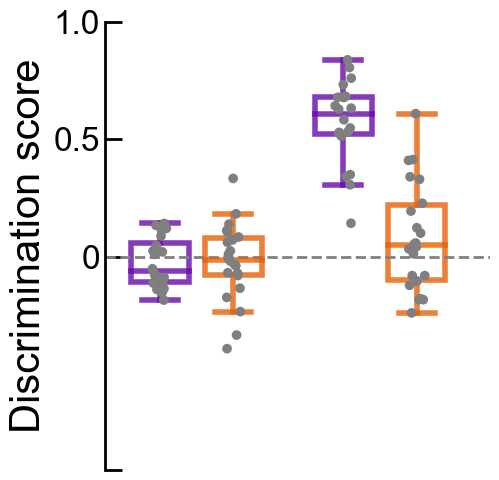

In [13]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['','****']
colors = ["C7","C7"]
colors_boxplot = ['#078f4f', "#680aab"]
colors_boxplot = ['#e66007', "#680aab"]
colors_boxplot = [ "#680aab",'#e66007']



ax = sns.stripplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    hue_order = ['n','y'],
    size=7,
    facecolors='none',
    edgecolors='black',
    palette=colors,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    hue_order = ['n','y'],
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)
plt.axhline(linewidth=2, color='grey',ls='--')

data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_linewidth(2)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[i%2]
    patch.set_edgecolor(col)
    patch.set_facecolor('None')
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

plt.legend([],[], frameon=False)

ax.set_xticklabels(['Cups','Social'], fontsize = 26)
ax.set_xticklabels([])
ax.set_xticks([])

ax.spines['left'].set_color('black')


ax.set_yticks([0,0.5,1], fontname='Arial')

ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Discrimination score', fontsize = 30, fontname='Arial')

ax.set_yticks([-0.90999,0,0.5,1], fontname='Arial')
ax.set_yticklabels(['','0','0.5','1.0'],fontname='Arial')

ax.set_ylim([-0.90999,1])
ax.set_xlim([-0.5,1.6])

significance(ax,1,data_ratio,newdf.loc[newdf['Experimental Condition']=='LTM']['Left preference'].max(),text=text_boxplot[1])

#plt.title("CS- arena half", fontsize=24,y=1.05)

fig = ax.get_figure()
adjust_box_widths(fig, 0.8)
fig.set_size_inches(5.1,4.9)
ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)

plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig2c_ScoresHalves_DREADDs.jpg",dpi=600,bbox_inches='tight')
plt.savefig('Fig2c_ScoresHalves_DREADDs.eps', dpi=600, format='eps')

